In [ ]:
# FINAURA – NIFTY 50 Data Preprocessing

# This notebook performs complete preprocessing of the NIFTY 50 dataset.

### Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Removal
# 6. Date Sorting
# 7. OHLC Validation
# 8. Return Calculation
# 9. Technical Feature Engineering
# 10. Volatility Calculation
# 11. Target Variable Creation
# 12. Data Quality Validation
# 13. Final Dataset Export

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
pd.set_option("display.max_columns",None)
pd.set_option("display.float_format",lambda x: f"{x:.4f}")

In [2]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "nifty50_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "nifty50_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\nifty50_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\nifty50_processed.csv


In [3]:
df=pd.read_csv(INPUT_FILE)
print("Dataset loaded successfully!")
print("Rows:" , df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 2385
Columns: 7


,Date,Adj Close,Close,High,Low,Open,Volume
0,2017-01-02,8179.5000,8179.5000,8212.0000,8133.7998,8210.0996,118300
1,2017-01-03,8192.2500,8192.2500,8219.0996,8148.6001,8196.0498,127300
2,2017-01-04,8190.5000,8190.5000,8218.5000,8180.8999,8202.6504,132400
3,2017-01-05,8273.7998,8273.7998,8282.6504,8223.7002,8226.6504,159100
4,2017-01-06,8243.7998,8243.7998,8306.8496,8233.2500,8281.8496,139400


In [4]:
print("number of rows:" , df.shape[0])
print("number of columns:",df.shape[1])

number of rows: 2385
number of columns: 7


In [5]:
print("Original columns:")
for col in df.columns:
    print(col)

Original columns:
Date
Adj Close
Close
High
Low
Open
Volume


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2385 entries, 0 to 2384
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2385 non-null   object 
 1   Adj Close  2385 non-null   float64
 2   Close      2385 non-null   float64
 3   High       2385 non-null   float64
 4   Low        2385 non-null   float64
 5   Open       2385 non-null   float64
 6   Volume     2385 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 130.6+ KB


In [7]:
df.describe()

,Adj Close,Close,High,Low,Open,Volume
count,2385.0000,2385.0000,2385.0000,2385.0000,2385.0000,2385.0000
mean,16500.4999,16500.4999,16584.0446,16412.8764,16509.4554,356171.9078
std,5633.7194,5633.7194,5653.3608,5613.5360,5632.9111,189214.3999
min,7610.2500,7610.2500,8036.9502,7511.1001,7735.1499,0.0000
25%,11022.2002,11022.2002,11072.5996,10935.4502,11018.1504,233800.0000
50%,16520.8496,16520.8496,16610.9492,16410.1992,16515.6504,298100.0000
75%,22217.4492,22217.4492,22368.6504,22079.4492,22231.1992,438200.0000
max,26328.5508,26328.5508,26373.1992,26210.0508,26333.6992,1811000.0000


In [8]:
df.columns=(
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ","_")
)
print(df.columns.tolist())

['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']


In [9]:
df["date"]=pd.to_datetime(
    df["date"],
    errors="coerce"
)
print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [10]:
numeric_columns=[
    "open",
    "high",
    "low",
    "close",
    "adj_close",
    "volume"
]

for col in numeric_columns:
    df[col]=pd.to_numeric(
        df[col],
        errors="coerce"
    )
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2385 entries, 0 to 2384
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       2385 non-null   datetime64[ns]
 1   adj_close  2385 non-null   float64       
 2   close      2385 non-null   float64       
 3   high       2385 non-null   float64       
 4   low        2385 non-null   float64       
 5   open       2385 non-null   float64       
 6   volume     2385 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 130.6 KB


In [11]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
adj_close,0,0.0000
close,0,0.0000
high,0,0.0000
low,0,0.0000
open,0,0.0000
volume,0,0.0000


In [12]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate rows: 0
Duplicate dates: 0


In [13]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["date"],
    keep="first"
)

print("Rows after duplicate removal:", len(df))

Rows after duplicate removal: 2385


In [14]:
print("Invalid dates:", df["date"].isna().sum())

Invalid dates: 0


In [15]:
df = df.sort_values(
    "date"
).reset_index(drop=True)

df.head()

,date,adj_close,close,high,low,open,volume
0,2017-01-02,8179.5000,8179.5000,8212.0000,8133.7998,8210.0996,118300
1,2017-01-03,8192.2500,8192.2500,8219.0996,8148.6001,8196.0498,127300
2,2017-01-04,8190.5000,8190.5000,8218.5000,8180.8999,8202.6504,132400
3,2017-01-05,8273.7998,8273.7998,8282.6504,8223.7002,8226.6504,159100
4,2017-01-06,8243.7998,8243.7998,8306.8496,8233.2500,8281.8496,139400


In [16]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 2017-01-02 00:00:00
End date: 2026-09-02 00:00:00


In [17]:
core_columns = [
    "open",
    "high",
    "low",
    "close"
]

print(
    df[core_columns]
    .isnull()
    .sum()
)

open     0
high     0
low      0
close    0
dtype: int64


In [18]:
for col in core_columns:
    invalid = (df[col] <= 0).sum()
    print(f"{col}: {invalid} invalid values")

open: 0 invalid values
high: 0 invalid values
low: 0 invalid values
close: 0 invalid values


In [19]:
invalid_ohlc = (
    (df["high"] < df["open"]) |
    (df["high"] < df["close"]) |
    (df["low"] > df["open"]) |
    (df["low"] > df["close"]) |
    (df["high"] < df["low"])
)

print("Invalid OHLC rows:", invalid_ohlc.sum())

Invalid OHLC rows: 0


In [20]:
print("Negative volume:", (df["volume"] < 0).sum())

Negative volume: 0


In [21]:
df["daily_return"] = (
    df["close"].pct_change()
)

df[
    ["date", "close", "daily_return"]
].head(10)

,date,close,daily_return
0,2017-01-02,8179.5000,NaN
1,2017-01-03,8192.2500,0.0016
2,2017-01-04,8190.5000,-0.0002
3,2017-01-05,8273.7998,0.0102
4,2017-01-06,8243.7998,-0.0036
5,2017-01-09,8236.0498,-0.0009
6,2017-01-10,8288.5996,0.0064
7,2017-01-11,8380.6504,0.0111
8,2017-01-12,8407.2002,0.0032
9,2017-01-13,8400.3496,-0.0008


In [22]:
df["log_return"] = np.log(
    df["close"] /
    df["close"].shift(1)
)

df[
    ["date", "close", "log_return"]
].head(10)

,date,close,log_return
0,2017-01-02,8179.5000,NaN
1,2017-01-03,8192.2500,0.0016
2,2017-01-04,8190.5000,-0.0002
3,2017-01-05,8273.7998,0.0101
4,2017-01-06,8243.7998,-0.0036
5,2017-01-09,8236.0498,-0.0009
6,2017-01-10,8288.5996,0.0064
7,2017-01-11,8380.6504,0.0110
8,2017-01-12,8407.2002,0.0032
9,2017-01-13,8400.3496,-0.0008


In [23]:
df["intraday_return"] = (
    (df["close"] - df["open"])
    / df["open"]
)

df[
    ["date", "intraday_return"]
].head()

,date,intraday_return
0,2017-01-02,-0.0037
1,2017-01-03,-0.0005
2,2017-01-04,-0.0015
3,2017-01-05,0.0057
4,2017-01-06,-0.0046


In [24]:
df["price_range"] = (
    (df["high"] - df["low"])
    / df["close"]
)

df[
    ["date", "price_range"]
].head()

,date,price_range
0,2017-01-02,0.0096
1,2017-01-03,0.0086
2,2017-01-04,0.0046
3,2017-01-05,0.0071
4,2017-01-06,0.0089


In [25]:
df["ma_5"] = (
    df["close"]
    .rolling(5)
    .mean()
)

df["ma_10"] = (
    df["close"]
    .rolling(10)
    .mean()
)

df["ma_20"] = (
    df["close"]
    .rolling(20)
    .mean()
)

df["ma_50"] = (
    df["close"]
    .rolling(50)
    .mean()
)

In [26]:
df["volatility_5d"] = (
    df["log_return"]
    .rolling(5)
    .std()
    * np.sqrt(252)
)

df["volatility_10d"] = (
    df["log_return"]
    .rolling(10)
    .std()
    * np.sqrt(252)
)

df["volatility_20d"] = (
    df["log_return"]
    .rolling(20)
    .std()
    * np.sqrt(252)
)

df[
    [
        "date",
        "volatility_5d",
        "volatility_10d",
        "volatility_20d"
    ]
].tail()

,date,volatility_5d,volatility_10d,volatility_20d
2380,2026-08-27,0.0660,0.0653,0.0814
2381,2026-08-28,0.0734,0.0696,0.0818
2382,2026-08-31,0.0772,0.0704,0.0553
2383,2026-09-01,0.0579,0.0656,0.0521
2384,2026-09-02,0.0601,0.0701,0.0543


In [27]:
df["momentum_5d"] = (
    df["close"] /
    df["close"].shift(5) - 1
)

df["momentum_20d"] = (
    df["close"] /
    df["close"].shift(20) - 1
)

In [28]:
running_max = (
    df["close"].cummax()
)

df["drawdown"] = (
    df["close"] /
    running_max - 1
)

df[
    ["date", "close", "drawdown"]
].tail()

,date,close,drawdown
2380,2026-08-27,24090.8496,-0.0850
2381,2026-08-28,24175.6504,-0.0818
2382,2026-08-31,24080.4004,-0.0854
2383,2026-09-01,24055.8008,-0.0863
2384,2026-09-02,23914.4492,-0.0917


In [29]:
df["volume_ma_20"] = (
    df["volume"]
    .rolling(20)
    .mean()
)

df["volume_ratio"] = (
    df["volume"] /
    df["volume_ma_20"]
)

In [30]:
future_5d_volatility = (
    df["log_return"]
    .rolling(window=5)
    .std()
    .shift(-5)
)

df["target_5d_volatility"] = (
    future_5d_volatility *
    np.sqrt(252)
)

In [31]:
target = "target_5d_volatility"

feature_columns = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "daily_return",
    "log_return",
    "intraday_return",
    "price_range",
    "ma_5",
    "ma_10",
    "ma_20",
    "ma_50",
    "volatility_5d",
    "volatility_10d",
    "volatility_20d",
    "momentum_5d",
    "momentum_20d",
    "drawdown",
    "volume_ma_20",
    "volume_ratio"
]

print("Number of features:", len(feature_columns))
print("Target:", target)

print("\nTarget accidentally included in features?")
print(target in feature_columns)

Number of features: 21
Target: target_5d_volatility

Target accidentally included in features?
False


In [32]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 186


In [33]:
df = df.dropna().reset_index(drop=True)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [34]:
print("Duplicate rows:", df.duplicated().sum())
print(
    "Duplicate dates:",
    df["date"].duplicated().sum()
)


Duplicate rows: 0
Duplicate dates: 0


In [35]:
print("========== FINAL DATASET ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

========== FINAL DATASET ==========
Rows: 2331
Columns: 24
Start date: 2017-03-15 00:00:00
End date: 2026-08-26 00:00:00
Missing values: 0
Duplicate rows: 0


In [36]:
print("Final columns:\n")

for i, col in enumerate(df.columns, 1):
    print(i, "-", col)

Final columns:

1 - date
2 - adj_close
3 - close
4 - high
5 - low
6 - open
7 - volume
8 - daily_return
9 - log_return
10 - intraday_return
11 - price_range
12 - ma_5
13 - ma_10
14 - ma_20
15 - ma_50
16 - volatility_5d
17 - volatility_10d
18 - volatility_20d
19 - momentum_5d
20 - momentum_20d
21 - drawdown
22 - volume_ma_20
23 - volume_ratio
24 - target_5d_volatility


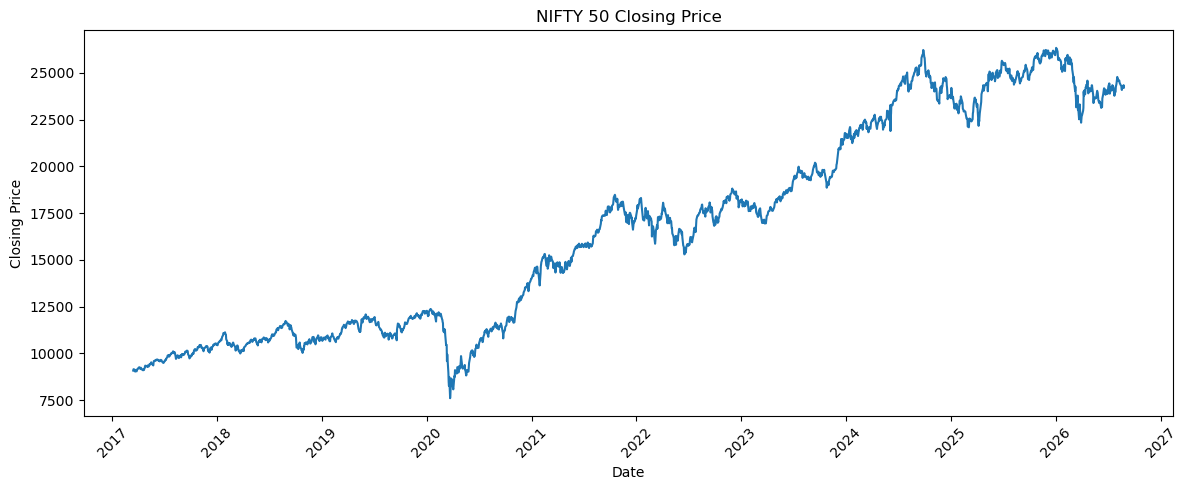

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["close"]
)

plt.title("NIFTY 50 Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

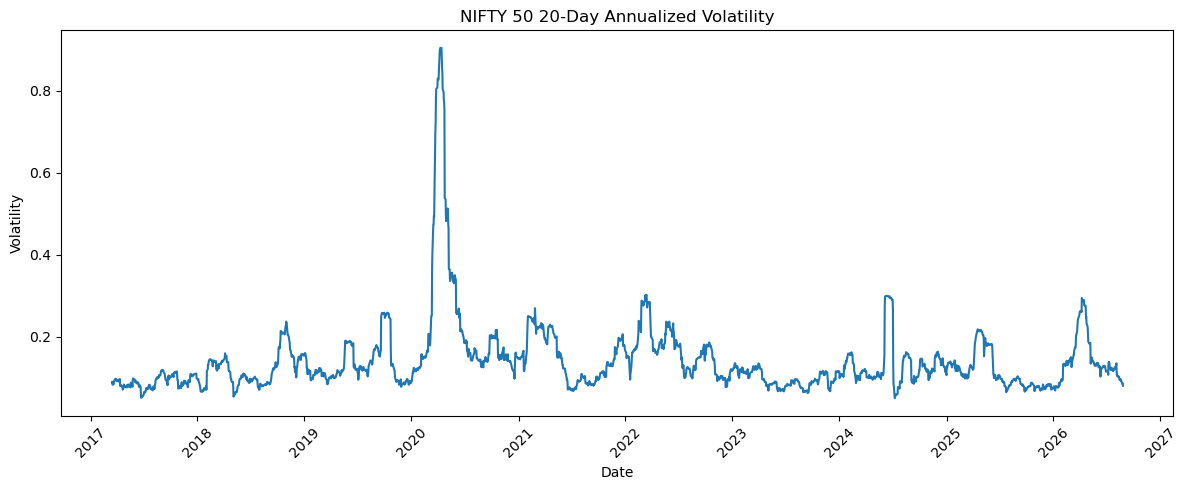

In [38]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["volatility_20d"]
)

plt.title("NIFTY 50 20-Day Annualized Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("Processed dataset saved successfully!")
print(OUTPUT_FILE)

Processed dataset saved successfully!
c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\nifty50_processed.csv


In [40]:
df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
0,2017-03-15,9084.7998,9084.7998,9106.5498,9075.5000,9086.8496,240600,-0.0002,-0.0002,-0.0002,0.0034,8991.5299,8961.1100,8907.8775,8663.4970,0.1247,0.1033,0.0887,0.0154,0.0318,-0.0002,216350.0000,1.1121,0.1018
1,2017-03-16,9153.7002,9153.7002,9158.4502,9128.5498,9129.6504,208600,0.0076,0.0076,0.0026,0.0033,9037.4100,8981.9000,8925.9475,8682.9810,0.1165,0.1035,0.0904,0.0257,0.0411,0.0000,217365.0000,0.9597,0.0945
2,2017-03-17,9160.0498,9160.0498,9218.4004,9147.5996,9207.7998,286700,0.0007,0.0007,-0.0052,0.0077,9084.0199,9007.9300,8947.7150,8702.3370,0.1155,0.0955,0.0830,0.0261,0.0499,0.0000,220895.0000,1.2979,0.0977
3,2017-03-20,9126.8496,9126.8496,9167.5996,9116.2998,9166.9502,332100,-0.0036,-0.0036,-0.0044,0.0056,9122.4799,9030.8600,8965.1575,8721.0639,0.1295,0.1000,0.0845,0.0215,0.0397,-0.0036,228270.0000,1.4549,0.1054
4,2017-03-21,9121.5000,9121.5000,9147.7500,9087.2002,9133.9502,247700,-0.0006,-0.0006,-0.0014,0.0066,9129.3799,9046.6649,8980.1475,8738.0179,0.0656,0.0972,0.0842,0.0038,0.0340,-0.0042,225740.0000,1.0973,0.1200


In [41]:
df.tail()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,volume_ma_20,volume_ratio,target_5d_volatility
2326,2026-08-20,24231.8496,24231.8496,24265.1504,24184.5508,24225.4492,253900,0.0064,0.0064,0.0003,0.0033,24223.7402,24357.6650,24346.3100,24160.2210,0.0724,0.0524,0.0932,-0.0067,0.0152,-0.0796,314405.0000,0.8076,0.0660
2327,2026-08-21,24252.0000,24252.0000,24284.0508,24206.8008,24284.0508,259300,0.0008,0.0008,-0.0013,0.0032,24200.9402,24325.8000,24370.5375,24182.0290,0.0741,0.0535,0.0913,-0.0047,0.0204,-0.0789,310675.0000,0.8346,0.0734
2328,2026-08-24,24219.0508,24219.0508,24313.0000,24144.3008,24285.0508,236300,-0.0014,-0.0014,-0.0027,0.0070,24187.2203,24289.3250,24381.6926,24193.9520,0.0716,0.0525,0.0857,-0.0028,0.0093,-0.0801,306520.0000,0.7709,0.0772
2329,2026-08-25,24334.5508,24334.5508,24334.5508,24115.4492,24175.7500,239500,0.0048,0.0048,0.0066,0.0090,24223.1504,24275.6102,24399.1526,24203.5650,0.0638,0.0578,0.0870,0.0074,0.0146,-0.0757,296605.0000,0.8075,0.0579
2330,2026-08-26,24207.7500,24207.7500,24378.5996,24207.7500,24341.9492,244800,-0.0052,-0.0052,-0.0055,0.0071,24249.0402,24252.7902,24397.0302,24207.9370,0.0741,0.0623,0.0804,0.0054,-0.0018,-0.0806,287635.0000,0.8511,0.0601
